#1. Import Libraries

In [ ]:
import os
import pandas as pd
import numpy as np
import kagglehub

from sklearn.model_selection import train_test_split

#2. Load the Dataset

In [ ]:
# Download dataset
path = kagglehub.dataset_download(
    "rohith203/traffic-volume-dataset"
)

print("Path to dataset files:", path)

# List downloaded files
print(os.listdir(path))

# Locate Train.csv
csv_path = os.path.join(path, "Train.csv")

# Load dataset
df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Using Colab cache for faster access to the 'traffic-volume-dataset' dataset.
Path to dataset files: /kaggle/input/traffic-volume-dataset
['sample_submission.csv', 'Train.csv', 'Test.csv']
Dataset loaded successfully!
Dataset shape: (33750, 15)


,date_time,is_holiday,air_pollution_index,humidity,wind_speed,wind_direction,visibility_in_miles,dew_point,temperature,rain_p_h,snow_p_h,clouds_all,weather_type,weather_description,traffic_volume
0,2012-10-02 09:00:00,NaN,121,89,2,329,1,1,288.28,0.0,0.0,40,Clouds,scattered clouds,5545
1,2012-10-02 10:00:00,NaN,178,67,3,330,1,1,289.36,0.0,0.0,75,Clouds,broken clouds,4516
2,2012-10-02 11:00:00,NaN,113,66,3,329,2,2,289.58,0.0,0.0,90,Clouds,overcast clouds,4767
3,2012-10-02 12:00:00,NaN,20,66,3,329,5,5,290.13,0.0,0.0,90,Clouds,overcast clouds,5026
4,2012-10-02 13:00:00,NaN,281,65,3,329,7,7,291.14,0.0,0.0,75,Clouds,broken clouds,4918


#3. Dataset Exploration

In [ ]:
# Display first five rows
display(df.head())

# Display column names
print("Columns:")
print(df.columns.tolist())

# Display dataset information
df.info()

# Count missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

# Count duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

,date_time,is_holiday,air_pollution_index,humidity,wind_speed,wind_direction,visibility_in_miles,dew_point,temperature,rain_p_h,snow_p_h,clouds_all,weather_type,weather_description,traffic_volume
0,2012-10-02 09:00:00,NaN,121,89,2,329,1,1,288.28,0.0,0.0,40,Clouds,scattered clouds,5545
1,2012-10-02 10:00:00,NaN,178,67,3,330,1,1,289.36,0.0,0.0,75,Clouds,broken clouds,4516
2,2012-10-02 11:00:00,NaN,113,66,3,329,2,2,289.58,0.0,0.0,90,Clouds,overcast clouds,4767
3,2012-10-02 12:00:00,NaN,20,66,3,329,5,5,290.13,0.0,0.0,90,Clouds,overcast clouds,5026
4,2012-10-02 13:00:00,NaN,281,65,3,329,7,7,291.14,0.0,0.0,75,Clouds,broken clouds,4918


Columns:
['date_time', 'is_holiday', 'air_pollution_index', 'humidity', 'wind_speed', 'wind_direction', 'visibility_in_miles', 'dew_point', 'temperature', 'rain_p_h', 'snow_p_h', 'clouds_all', 'weather_type', 'weather_description', 'traffic_volume']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33750 entries, 0 to 33749
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date_time            33750 non-null  object 
 1   is_holiday           43 non-null     object 
 2   air_pollution_index  33750 non-null  int64  
 3   humidity             33750 non-null  int64  
 4   wind_speed           33750 non-null  int64  
 5   wind_direction       33750 non-null  int64  
 6   visibility_in_miles  33750 non-null  int64  
 7   dew_point            33750 non-null  int64  
 8   temperature          33750 non-null  float64
 9   rain_p_h             33750 non-null  float64
 10  snow_p_h             33750 non-null 

#4. Data Cleaning

In [ ]:
# Save original row count
original_rows = len(df)

# Remove is_holiday column
df = df.drop(columns=["is_holiday"], errors="ignore")

# Remove duplicate rows
df = df.drop_duplicates()

# Display cleaning results
print("Original rows:", original_rows)
print("Rows after removing duplicates:", len(df))
print("Columns after removing is_holiday:", df.shape[1])

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nCleaned Dataset Shape:", df.shape)

Original rows: 33750
Rows after removing duplicates: 33750
Columns after removing is_holiday: 14

Missing Values After Cleaning:
date_time              0
air_pollution_index    0
humidity               0
wind_speed             0
wind_direction         0
visibility_in_miles    0
dew_point              0
temperature            0
rain_p_h               0
snow_p_h               0
clouds_all             0
weather_type           0
weather_description    0
traffic_volume         0
dtype: int64

Cleaned Dataset Shape: (33750, 14)


#5. Handling Missing Values

In [ ]:
# Remove rows where the target is missing
df = df.dropna(subset=["traffic_volume"]).copy()

# Separate numerical and categorical columns
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    exclude=np.number
).columns.tolist()

# Fill missing numerical values using the median
for column in numerical_columns:
    df[column] = df[column].fillna(df[column].median())

# Fill missing categorical values using the mode
for column in categorical_columns:
    if df[column].isnull().any():
        mode_values = df[column].mode()

        if not mode_values.empty:
            df[column] = df[column].fillna(mode_values.iloc[0])
# Extract date and time features
df["date_time"] = pd.to_datetime(df["date_time"])

df["hour"] = df["date_time"].dt.hour
df["day"] = df["date_time"].dt.day
df["month"] = df["date_time"].dt.month
df["day_of_week"] = df["date_time"].dt.dayofweek

# Remove original datetime column
df = df.drop(columns=["date_time"])

print("Dataset shape:", df.shape)
print(df.columns.tolist())
print("Remaining missing values:", df.isnull().sum().sum())
print("Dataset shape after cleaning:", df.shape)

Dataset shape: (33750, 17)
['air_pollution_index', 'humidity', 'wind_speed', 'wind_direction', 'visibility_in_miles', 'dew_point', 'temperature', 'rain_p_h', 'snow_p_h', 'clouds_all', 'weather_type', 'weather_description', 'traffic_volume', 'hour', 'day', 'month', 'day_of_week']
Remaining missing values: 0
Dataset shape after cleaning: (33750, 17)


#6. Feature and Target Preparation

In [ ]:
# Separate features and target
X = df.drop(columns=["traffic_volume"]).copy()
y = df["traffic_volume"].copy()

# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:", categorical_columns)
print("Features before encoding:", X.shape)
print("Target shape:", y.shape)

Categorical columns: ['weather_type', 'weather_description']
Features before encoding: (33750, 16)
Target shape: (33750,)


#7. Training and Testing Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train_raw.shape)
print("Testing features:", X_test_raw.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (27000, 16)
Testing features: (6750, 16)
Training target: (27000,)
Testing target: (6750,)


#8. Encoding Categorical Features

In [ ]:
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import hstack, csr_matrix

# Identify categorical and numerical columns
categorical_columns = X_train_raw.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_columns = X_train_raw.select_dtypes(
    include=np.number
).columns.tolist()

# Encode categorical features efficiently
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

X_train_cat = encoder.fit_transform(
    X_train_raw[categorical_columns]
)

X_test_cat = encoder.transform(
    X_test_raw[categorical_columns]
)

# Convert numerical features to sparse matrices
X_train_num = csr_matrix(
    X_train_raw[numeric_columns].to_numpy(dtype=np.float32)
)

X_test_num = csr_matrix(
    X_test_raw[numeric_columns].to_numpy(dtype=np.float32)
)

# Combine numerical and categorical features
X_train = hstack(
    [X_train_num, X_train_cat],
    format="csr"
)

X_test = hstack(
    [X_test_num, X_test_cat],
    format="csr"
)

print("Training features after encoding:", X_train.shape)
print("Testing features after encoding:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features after encoding: (27000, 63)
Testing features after encoding: (6750, 63)
Training target: (27000,)
Testing target: (6750,)


#9. Create Training Subsets

In [ ]:
# Create 25% training subset
X_train_25 = X_train[:6750]
y_train_25 = y_train.iloc[:6750]

# Create 50% training subset
X_train_50 = X_train[:13500]
y_train_50 = y_train.iloc[:13500]

# Use 100% of the training data
X_train_100 = X_train
y_train_100 = y_train

# Display subset sizes
print("25% training subset:", X_train_25.shape, y_train_25.shape)
print("50% training subset:", X_train_50.shape, y_train_50.shape)
print("100% training subset:", X_train_100.shape, y_train_100.shape)
print("Fixed testing set:", X_test.shape, y_test.shape)

25% training subset: (6750, 63) (6750,)
50% training subset: (13500, 63) (13500,)
100% training subset: (27000, 63) (27000,)
Fixed testing set: (6750, 63) (6750,)


#10. Final Data Verification

In [ ]:
# Check missing values in sparse matrices
print("Missing values in training features:", np.isnan(X_train.data).sum())
print("Missing values in testing features:", np.isnan(X_test.data).sum())

# Check target missing values
print(
    "Target missing values:",
    y_train.isnull().sum() + y_test.isnull().sum()
)

# Check feature dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

# Verify feature counts match
print(
    "Feature counts match:",
    X_train.shape[1] == X_test.shape[1]
)

Missing values in training features: 0
Missing values in testing features: 0
Target missing values: 0
Training features: (27000, 63)
Testing features: (6750, 63)
Feature counts match: True


#11. Import Model and Evaluation Libraries

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, ParameterGrid
import pandas as pd
import numpy as np
import joblib

#12. Prepare Training and Validation Data

In [ ]:
X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_model_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (21600, 63)
Validation data: (5400, 63)
Testing data: (6750, 63)


#13. Define Random Forest Hyperparameters

In [ ]:
n_estimators_values = [50, 100]
max_depth_values = [10, 20]
min_samples_split_values = [2, 5]
min_samples_leaf_values = [1, 2]

total_experiments = (
    len(n_estimators_values)
    * len(max_depth_values)
    * len(min_samples_split_values)
    * len(min_samples_leaf_values)
)

print("Total Experiments:", total_experiments)

Total Experiments: 16


#14. Sequential Hyperparameter Tuning

In [ ]:
import time

tuning_results = []
experiment = 0

tuning_start = time.perf_counter()
for n_estimators in n_estimators_values:
    for max_depth in max_depth_values:
        for min_samples_split in min_samples_split_values:
            for min_samples_leaf in min_samples_leaf_values:
                experiment += 1
                model = RandomForestRegressor(
                    n_estimators=n_estimators,
                    max_depth=max_depth,
                    min_samples_split=min_samples_split,
                    min_samples_leaf=min_samples_leaf,
                    n_jobs=1,
                    random_state=42
                )
                model.fit(X_model_train, y_model_train)
                predictions = model.predict(X_val)
                rmse = np.sqrt(
                    mean_squared_error(y_val, predictions)
                )
                mae = mean_absolute_error(
                    y_val, predictions
                )
                r2 = r2_score(
                    y_val, predictions
                )
                tuning_results.append({
                    "experiment": experiment,
                    "n_estimators": n_estimators,
                    "max_depth": max_depth,
                    "min_samples_split": min_samples_split,
                    "min_samples_leaf": min_samples_leaf,
                    "RMSE": rmse,
                    "MAE": mae,
                    "R2": r2
                })

                print(
                    f"Experiment {experiment}/{total_experiments} "
                    f"| Trees: {n_estimators} "
                    f"| Depth: {max_depth} "
                    f"| Split: {min_samples_split} "
                    f"| Leaf: {min_samples_leaf} "
                    f"| RMSE: {rmse:.4f}"
                )

tuning_time = time.perf_counter() - tuning_start

print("\nSequential Hyperparameter Tuning Completed")
print(f"Total Experiments: {experiment}")
print(f"Total Execution Time: {tuning_time:.2f} seconds")
print(f"Total Execution Time: {tuning_time / 60:.2f} minutes")

Experiment 1/16 | Trees: 50 | Depth: 10 | Split: 2 | Leaf: 1 | RMSE: 466.3370
Experiment 2/16 | Trees: 50 | Depth: 10 | Split: 2 | Leaf: 2 | RMSE: 464.3618
Experiment 3/16 | Trees: 50 | Depth: 10 | Split: 5 | Leaf: 1 | RMSE: 466.5691
Experiment 4/16 | Trees: 50 | Depth: 10 | Split: 5 | Leaf: 2 | RMSE: 464.1939
Experiment 5/16 | Trees: 50 | Depth: 20 | Split: 2 | Leaf: 1 | RMSE: 430.2173
Experiment 6/16 | Trees: 50 | Depth: 20 | Split: 2 | Leaf: 2 | RMSE: 426.7583
Experiment 7/16 | Trees: 50 | Depth: 20 | Split: 5 | Leaf: 1 | RMSE: 430.3987
Experiment 8/16 | Trees: 50 | Depth: 20 | Split: 5 | Leaf: 2 | RMSE: 427.6813
Experiment 9/16 | Trees: 100 | Depth: 10 | Split: 2 | Leaf: 1 | RMSE: 465.3527
Experiment 10/16 | Trees: 100 | Depth: 10 | Split: 2 | Leaf: 2 | RMSE: 463.7489
Experiment 11/16 | Trees: 100 | Depth: 10 | Split: 5 | Leaf: 1 | RMSE: 465.5750
Experiment 12/16 | Trees: 100 | Depth: 10 | Split: 5 | Leaf: 2 | RMSE: 463.8544
Experiment 13/16 | Trees: 100 | Depth: 20 | Split: 2 | Le

#15. Hyperparameter Tuning Results

In [ ]:
results_df = pd.DataFrame(tuning_results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df.head(10))

,experiment,n_estimators,max_depth,min_samples_split,min_samples_leaf,RMSE,MAE,R2
0,14,100,20,2,2,426.620479,252.416813,0.953485
1,6,50,20,2,2,426.758348,253.108622,0.953455
2,16,100,20,5,2,427.343960,253.240780,0.953327
3,8,50,20,5,2,427.681339,253.852247,0.953253
4,13,100,20,2,1,428.611125,255.815728,0.953050
5,15,100,20,5,1,429.063200,256.067811,0.952951
6,5,50,20,2,1,430.217299,256.941895,0.952697
7,7,50,20,5,1,430.398694,257.035813,0.952658
8,10,100,10,2,2,463.748863,277.022752,0.945036
9,12,100,10,5,2,463.854408,277.203413,0.945011


#16. Select Best Hyperparameters

In [ ]:
best_result = results_df.iloc[0]

best_params = {
    "n_estimators": int(best_result["n_estimators"]),
    "max_depth": (
        None
        if pd.isna(best_result["max_depth"])
        else int(best_result["max_depth"])
    ),
    "min_samples_split": int(best_result["min_samples_split"]),
    "min_samples_leaf": int(best_result["min_samples_leaf"])
}

print("Best Hyperparameters:")
print(best_params)

print("Best Validation RMSE:", best_result["RMSE"])
print("Best Validation MAE:", best_result["MAE"])
print("Best Validation R2:", best_result["R2"])

Best Hyperparameters:
{'n_estimators': 100, 'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 2}
Best Validation RMSE: 426.62047870811494
Best Validation MAE: 252.41681295128853
Best Validation R2: 0.9534850864244153


#17. Train the Final Random Forest Model

In [ ]:
best_model = RandomForestRegressor(
    **best_params,
    n_jobs=1,
    random_state=42
)

best_model.fit(X_train, y_train)

print("Final model trained successfully.")

Final model trained successfully.


#18. Evaluate the Final Model

In [ ]:
y_pred = best_model.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_mae = mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print("Final Model Performance")
print(f"RMSE: {test_rmse:.4f}")
print(f"MAE: {test_mae:.4f}")
print(f"R2 Score: {test_r2:.4f}")

Final Model Performance
RMSE: 418.2780
MAE: 239.6753
R2 Score: 0.9562


#19. Save Hyperparameter Tuning Results and Best Model

In [ ]:
results_df.to_csv(
    "sequential_hyperparameter_results.csv",
    index=False
)

joblib.dump(
    best_model,
    "best_random_forest_sequential.pkl"
)

joblib.dump(
    best_params,
    "best_hyperparameters.pkl"
)

print("Results and model saved successfully.")

Results and model saved successfully.


#20. Sequential Benchmarking & Testing


In [ ]:
import time
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

data_sizes = {
    "25%": (X_train_25, y_train_25),
    "50%": (X_train_50, y_train_50),
    "100%": (X_train_100, y_train_100)
}

benchmark_results = []

for size, (X_data, y_data) in data_sizes.items():
    for run in range(1, 4):

        benchmark_model = RandomForestRegressor(
            **best_params,
            n_jobs=1,
            random_state=42
        )

        start = time.perf_counter()
        benchmark_model.fit(X_data, y_data)
        training_time = time.perf_counter() - start

        start = time.perf_counter()
        predictions = benchmark_model.predict(X_test)
        prediction_time = time.perf_counter() - start

        rmse = np.sqrt(mean_squared_error(y_test, predictions))

        benchmark_results.append({
            "Data Size": size,
            "Run": run,
            "Training Time": training_time,
            "Prediction Time": prediction_time,
            "RMSE": rmse
        })

        print(
            f"{size} | Run {run}/3 | "
            f"Training: {training_time:.2f}s | "
            f"Prediction: {prediction_time:.2f}s"
        )

benchmark_df = pd.DataFrame(benchmark_results)

display(benchmark_df)

print("\nAverage Execution Times:")
display(
    benchmark_df.groupby("Data Size", sort=False)[
        ["Training Time", "Prediction Time"]
    ].mean()
)

25% | Run 1/3 | Training: 20.62s | Prediction: 0.12s
25% | Run 2/3 | Training: 27.48s | Prediction: 0.14s
25% | Run 3/3 | Training: 20.97s | Prediction: 0.12s
50% | Run 1/3 | Training: 54.21s | Prediction: 0.15s
50% | Run 2/3 | Training: 54.17s | Prediction: 0.17s
50% | Run 3/3 | Training: 54.08s | Prediction: 0.15s
100% | Run 1/3 | Training: 137.99s | Prediction: 0.20s
100% | Run 2/3 | Training: 139.25s | Prediction: 0.17s
100% | Run 3/3 | Training: 139.96s | Prediction: 0.17s


,Data Size,Run,Training Time,Prediction Time,RMSE
0,25%,1,20.621192,0.115866,472.009055
1,25%,2,27.475837,0.140195,472.009055
2,25%,3,20.965820,0.116423,472.009055
3,50%,1,54.209955,0.148240,450.996846
4,50%,2,54.167435,0.166141,450.996846
5,50%,3,54.079401,0.148287,450.996846
6,100%,1,137.989011,0.201119,418.277966
7,100%,2,139.253707,0.173023,418.277966
8,100%,3,139.963542,0.174654,418.277966



Average Execution Times:


,Training Time,Prediction Time
Data Size,,
25%,23.020949,0.124162
50%,54.152264,0.154223
100%,139.068754,0.182932


#21. Execution Time Analysis

In [ ]:
avg_times = benchmark_df.groupby("Data Size", sort=False)[
    ["Training Time", "Prediction Time"]
].mean()

avg_times["Total Time"] = (
    avg_times["Training Time"] + avg_times["Prediction Time"]
)

display(avg_times.round(2))

slowest_stage = avg_times[
    ["Training Time", "Prediction Time"]
].mean().idxmax()

print(f"Slowest Measured Stage: {slowest_stage}")

benchmark_df.to_csv(
    "sequential_benchmark_results.csv",
    index=False
)

print("Benchmark results saved successfully.")

,Training Time,Prediction Time,Total Time
Data Size,,,
25%,23.02,0.12,23.15
50%,54.15,0.15,54.31
100%,139.07,0.18,139.25


Slowest Measured Stage: Training Time
Benchmark results saved successfully.


#22. Sequential Training Time Visualization

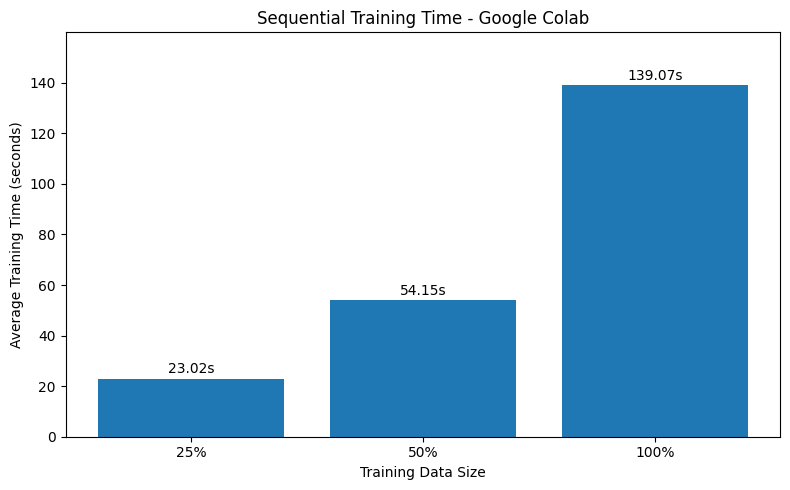

In [ ]:
import matplotlib.pyplot as plt

sizes = ["25%", "50%", "100%"]
times = avg_times.loc[sizes, "Training Time"]

plt.figure(figsize=(8, 5))
bars = plt.bar(sizes, times)

plt.title("Sequential Training Time - Google Colab")
plt.xlabel("Training Data Size")
plt.ylabel("Average Training Time (seconds)")

for bar, value in zip(bars, times):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        f"{value:.2f}s",
        ha="center"
    )

plt.ylim(0, max(times) * 1.15)
plt.tight_layout()
plt.savefig("sequential_training_time_colab.png", dpi=200)
plt.show()

#22. Sequential Execution Time Summary

In [ ]:
import numpy as np

tuning_time = np.nan

In [ ]:
execution_summary = pd.DataFrame({
    "Metric": [
        "Hyperparameter Tuning (16 Experiments)",
        "Model Training (100% Data)",
        "Model Prediction (100% Data)"
    ],
    "Execution Time (seconds)": [
        tuning_time,
        avg_times.loc["100%", "Training Time"],
        avg_times.loc["100%", "Prediction Time"]
    ]
})

display(execution_summary.round(2))

,Metric,Execution Time (seconds)
0,Hyperparameter Tuning (16 Experiments),NaN
1,Model Training (100% Data),139.07
2,Model Prediction (100% Data),0.18


## 23. Task 2 – Unsynchronised Parallel Hyperparameter Tuning

In [ ]:

import multiprocessing as mp
import time
from itertools import product

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


experiment = None
tuning_results = None

X_train_shared = None
y_train_shared = None
X_val_shared = None
y_val_shared = None


def initialize_worker(shared_experiment, shared_results,
                      X_train, y_train, X_validation, y_validation):

    global experiment, tuning_results
    global X_train_shared, y_train_shared, X_val_shared, y_val_shared

    experiment = shared_experiment
    tuning_results = shared_results

    X_train_shared = X_train
    y_train_shared = y_train
    X_val_shared = X_validation
    y_val_shared = y_validation


def run_experiment(params):

    global experiment, tuning_results

    current_id = experiment.value
    time.sleep(0.05)
    experiment.value = current_id + 1

    model = RandomForestRegressor(
        n_estimators=params[0],
        max_depth=params[1],
        min_samples_split=params[2],
        min_samples_leaf=params[3],
        n_jobs=1,
        random_state=42
    )

    model.fit(X_train_shared, y_train_shared)
    predictions = model.predict(X_val_shared)

    rmse = mean_squared_error(y_val_shared, predictions) ** 0.5
    mae = mean_absolute_error(y_val_shared, predictions)
    r2 = r2_score(y_val_shared, predictions)

    result = {
        "experiment": current_id + 1,
        "n_estimators": params[0],
        "max_depth": params[1],
        "min_samples_split": params[2],
        "min_samples_leaf": params[3],
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }

    tuning_results[current_id] = result

    return result


parameter_combinations = list(product(
    n_estimators_values,
    max_depth_values,
    min_samples_split_values,
    min_samples_leaf_values
))

start_time = time.perf_counter()

with mp.Manager() as manager:

    shared_experiment = manager.Value('i', 0)
    shared_tuning_results = manager.list(
        [None] * len(parameter_combinations)
    )

    with mp.Pool(
        processes=4,
        initializer=initialize_worker,
        initargs=(
            shared_experiment,
            shared_tuning_results,
            X_model_train,
            y_model_train,
            X_val,
            y_val
        )
    ) as pool:

        pool.map(run_experiment, parameter_combinations)

    execution_time = time.perf_counter() - start_time

    unsync_results = list(shared_tuning_results)
    final_counter = shared_experiment.value

print("Unsynchronised Parallel Hyperparameter Tuning")
print("----------------------------------------------")
print("Expected Experiments:", len(parameter_combinations))
print("Counter Value:", final_counter)
print("Recorded Results:", sum(x is not None for x in unsync_results))
print("Execution Time:", round(execution_time, 2), "seconds")

print("\nExperiment IDs:")
print([
    x["experiment"] if x is not None else None
    for x in unsync_results
])

print("\nExperiment Results:")
for result in unsync_results:
    print(result)


Unsynchronised Parallel Hyperparameter Tuning
----------------------------------------------
Expected Experiments: 16
Counter Value: 13
Recorded Results: 13
Execution Time: 722.65 seconds

Experiment IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, None, None, None]

Experiment Results:
{'experiment': 1, 'n_estimators': 50, 'max_depth': 10, 'min_samples_split': 2, 'min_samples_leaf': 1, 'RMSE': 466.33698632911546, 'MAE': 279.11843232473177, 'R2': 0.9444212794914183}
{'experiment': 2, 'n_estimators': 50, 'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 1, 'RMSE': 430.2172986365508, 'MAE': 256.94189471013453, 'R2': 0.9526974494000757}
{'experiment': 3, 'n_estimators': 50, 'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 2, 'RMSE': 426.75834775542097, 'MAE': 253.10862165738394, 'R2': 0.9534550175300921}
{'experiment': 4, 'n_estimators': 50, 'max_depth': 20, 'min_samples_split': 5, 'min_samples_leaf': 1, 'RMSE': 430.398693870806, 'MAE': 257.035812870633, 'R2': 0.952

## 24. RACE CONDITION IN BENCHMARK RESULTS
## Experiment Setup and Data Preparation

In [ ]:

import multiprocessing as mp
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

# Dataset sizes
benchmark_data = {
    "25%": (X_train_25, y_train_25),
    "50%": (X_train_50, y_train_50),
    "100%": (X_train_100, y_train_100)
}

# Three runs for each dataset size
benchmark_tasks = [
    (size, run)
    for size in benchmark_data
    for run in range(1, 4)
]

# Shared variables
benchmark_counter_shared = None
benchmark_results_shared = None
benchmark_data_shared = None

print("Experiment B setup completed.")
print("Total benchmark tasks:", len(benchmark_tasks))


Experiment B setup completed.
Total benchmark tasks: 9


## 25. Parallel Benchmarking Function

In [ ]:


def initialize_benchmark_worker(data, counter, results):

    global benchmark_data_shared
    global benchmark_counter_shared
    global benchmark_results_shared

    benchmark_data_shared = data
    benchmark_counter_shared = counter
    benchmark_results_shared = results


def run_parallel_benchmark(task):

    size, run = task

    # Unsynchronized counter update
    current_id = benchmark_counter_shared.value

    time.sleep(0.02)

    benchmark_counter_shared.value = current_id + 1

    X_data, y_data = benchmark_data_shared[size]

    model = RandomForestRegressor(
        **best_params,
        n_jobs=1,
        random_state=42
    )

    # Training time
    start = time.perf_counter()
    model.fit(X_data, y_data)
    training_time = time.perf_counter() - start

    # Prediction time
    start = time.perf_counter()
    predictions = model.predict(X_test)
    prediction_time = time.perf_counter() - start

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    result = {
        "Experiment ID": current_id + 1,
        "Data Size": size,
        "Run": run,
        "Training Time": training_time,
        "Prediction Time": prediction_time,
        "Total Time": training_time + prediction_time,
        "RMSE": rmse
    }

    # Shared list update without synchronization
    benchmark_results_shared[current_id] = result


## 26. Running Unsynchronized Parallel Experiments

In [ ]:

# Experiment B - Parallel Execution

process_counts = [1, 2, 4, 8]

benchmark_summary = []
all_parallel_results = []

for num_processes in process_counts:

    print("\nRunning with", num_processes, "Processes")

    start_time = time.perf_counter()

    with mp.Manager() as manager:

        shared_counter = manager.Value('i', 0)

        shared_results = manager.list(
            [None] * len(benchmark_tasks)
        )

        with mp.Pool(
            processes=num_processes,
            initializer=initialize_benchmark_worker,
            initargs=(
                benchmark_data,
                shared_counter,
                shared_results
            )
        ) as pool:

            pool.map(
                run_parallel_benchmark,
                benchmark_tasks
            )

        execution_time = time.perf_counter() - start_time

        recorded_results = list(shared_results)
        final_counter = shared_counter.value

    valid_results = [
        result for result in recorded_results
        if result is not None
    ]

    missing_results = (
        len(benchmark_tasks) - len(valid_results)
    )

    for result in valid_results:
        result["Processes"] = num_processes
        all_parallel_results.append(result)

    benchmark_summary.append({
        "Processes": num_processes,
        "Expected Results": len(benchmark_tasks),
        "Recorded Results": len(valid_results),
        "Missing Results": missing_results,
        "Counter Value": final_counter,
        "Execution Time (s)": execution_time
    })

    print("Expected:", len(benchmark_tasks))
    print("Recorded:", len(valid_results))
    print("Missing:", missing_results)
    print("Counter:", final_counter)
    print("Execution Time:", round(execution_time, 2), "seconds")



Running with 1 Processes
Expected: 9
Recorded: 9
Missing: 0
Counter: 9
Execution Time: 654.01 seconds

Running with 2 Processes
Expected: 9
Recorded: 8
Missing: 1
Counter: 8
Execution Time: 504.0 seconds

Running with 4 Processes
Expected: 9
Recorded: 5
Missing: 4
Counter: 5
Execution Time: 505.48 seconds

Running with 8 Processes
Expected: 9
Recorded: 2
Missing: 7
Counter: 2
Execution Time: 498.78 seconds


## 27. Results Analysis and Performance Comparison

In [ ]:

# Experiment B - Results and Performance Comparison

parallel_benchmark_df = pd.DataFrame(
    all_parallel_results
)

parallel_summary_df = pd.DataFrame(
    benchmark_summary
)

# Calculate speed-up
baseline_time = parallel_summary_df.loc[
    parallel_summary_df["Processes"] == 1,
    "Execution Time (s)"
].iloc[0]

parallel_summary_df["Speed-up"] = (
    baseline_time /
    parallel_summary_df["Execution Time (s)"]
)

print("DETAILED BENCHMARK RESULTS")
display(parallel_benchmark_df)

print("\nPERFORMANCE COMPARISON")
display(parallel_summary_df.round(3))

# Save results
parallel_benchmark_df.to_csv(
    "parallel_benchmark_results.csv",
    index=False
)

parallel_summary_df.to_csv(
    "benchmark_performance_summary.csv",
    index=False
)

print("\nResults saved successfully.")


DETAILED BENCHMARK RESULTS


,Experiment ID,Data Size,Run,Training Time,Prediction Time,Total Time,RMSE,Processes
0,1,25%,1,21.094978,0.139919,21.234898,472.009055,1
1,2,25%,2,21.236008,0.120282,21.356290,472.009055,1
2,3,25%,3,22.797354,0.117878,22.915232,472.009055,1
3,4,50%,1,56.779722,0.143307,56.923029,450.996846,1
4,5,50%,2,55.377796,0.170225,55.548021,450.996846,1
5,6,50%,3,54.629179,0.145726,54.774906,450.996846,1
6,7,100%,1,140.453488,0.203569,140.657058,418.277966,1
7,8,100%,2,140.345736,0.177359,140.523095,418.277966,1
8,9,100%,3,139.614535,0.175826,139.790361,418.277966,1
9,1,25%,1,32.209290,0.279639,32.488930,472.009055,2



PERFORMANCE COMPARISON


,Processes,Expected Results,Recorded Results,Missing Results,Counter Value,Execution Time (s),Speed-up
0,1,9,9,0,9,654.013,1.000
1,2,9,8,1,8,504.001,1.298
2,4,9,5,4,5,505.475,1.294
3,8,9,2,7,2,498.783,1.311



Results saved successfully.


## 28. Task 3 : Lock Synchronisation (Hyperparameter Tuning)

In [ ]:
def initialize_worker_lock(shared_experiment, shared_results, shared_lock,
                           X_train, y_train, X_validation, y_validation):

    global experiment, tuning_results, lock
    global X_train_shared, y_train_shared, X_val_shared, y_val_shared

    experiment = shared_experiment
    tuning_results = shared_results
    lock = shared_lock

    X_train_shared = X_train
    y_train_shared = y_train
    X_val_shared = X_validation
    y_val_shared = y_validation


def run_experiment_lock(params):

    global experiment, tuning_results, lock

    with lock:
        current_id = experiment.value
        time.sleep(0.05)
        experiment.value = current_id + 1

    model = RandomForestRegressor(
        n_estimators=params[0],
        max_depth=params[1],
        min_samples_split=params[2],
        min_samples_leaf=params[3],
        n_jobs=1,
        random_state=42
    )

    model.fit(X_train_shared, y_train_shared)
    predictions = model.predict(X_val_shared)

    rmse = mean_squared_error(y_val_shared, predictions) ** 0.5
    mae = mean_absolute_error(y_val_shared, predictions)
    r2 = r2_score(y_val_shared, predictions)

    result = {
        "experiment": current_id + 1,
        "n_estimators": params[0],
        "max_depth": params[1],
        "min_samples_split": params[2],
        "min_samples_leaf": params[3],
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }

    tuning_results[current_id] = result

    return result


start_time = time.perf_counter()

with mp.Manager() as manager:

    shared_experiment = manager.Value('i', 0)
    shared_tuning_results = manager.list(
        [None] * len(parameter_combinations)
    )
    shared_lock = manager.Lock()

    with mp.Pool(
        processes=4,
        initializer=initialize_worker_lock,
        initargs=(
            shared_experiment,
            shared_tuning_results,
            shared_lock,
            X_model_train,
            y_model_train,
            X_val,
            y_val
        )
    ) as pool:

        pool.map(run_experiment_lock, parameter_combinations)

    execution_time = time.perf_counter() - start_time

    lock_results = list(shared_tuning_results)
    final_counter = shared_experiment.value

print("Lock Version - Parallel Hyperparameter Tuning")
print("----------------------------------------------")
print("Expected Experiments:", len(parameter_combinations))
print("Counter Value:", final_counter)
print("Recorded Results:", sum(x is not None for x in lock_results))
print("Execution Time:", round(execution_time, 2), "seconds")

print("\nExperiment IDs:")
print([
    x["experiment"] if x is not None else None
    for x in lock_results
])

print("\nExperiment Results:")
for result in lock_results:
    print(result)

Lock Version - Parallel Hyperparameter Tuning
----------------------------------------------
Expected Experiments: 16
Counter Value: 16
Recorded Results: 16
Execution Time: 716.68 seconds

Experiment IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]

Experiment Results:
{'experiment': 1, 'n_estimators': 50, 'max_depth': 10, 'min_samples_split': 2, 'min_samples_leaf': 1, 'RMSE': 466.33698632911546, 'MAE': 279.11843232473177, 'R2': 0.9444212794914183}
{'experiment': 2, 'n_estimators': 50, 'max_depth': 10, 'min_samples_split': 2, 'min_samples_leaf': 2, 'RMSE': 464.3618250543568, 'MAE': 277.6660520241153, 'R2': 0.9448910876370997}
{'experiment': 3, 'n_estimators': 50, 'max_depth': 10, 'min_samples_split': 5, 'min_samples_leaf': 1, 'RMSE': 466.56909748232476, 'MAE': 279.6934054412484, 'R2': 0.9443659390325877}
{'experiment': 4, 'n_estimators': 50, 'max_depth': 10, 'min_samples_split': 5, 'min_samples_leaf': 2, 'RMSE': 464.19393671123373, 'MAE': 277.5751017757644, 'R2': 0.94493092

## 29. Task 3 : Lock Synchronisation (Benchmark Results)

In [ ]:
def initialize_benchmark_worker_lock(data, counter, results, shared_lock):

    global benchmark_data_shared
    global benchmark_counter_shared
    global benchmark_results_shared
    global benchmark_lock

    benchmark_data_shared = data
    benchmark_counter_shared = counter
    benchmark_results_shared = results
    benchmark_lock = shared_lock


def run_parallel_benchmark_lock(task):

    size, run = task

    with benchmark_lock:
        current_id = benchmark_counter_shared.value
        time.sleep(0.02)
        benchmark_counter_shared.value = current_id + 1

    X_data, y_data = benchmark_data_shared[size]

    model = RandomForestRegressor(
        **best_params,
        n_jobs=1,
        random_state=42
    )

    start = time.perf_counter()
    model.fit(X_data, y_data)
    training_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(X_test)
    prediction_time = time.perf_counter() - start

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    result = {
        "Experiment ID": current_id + 1,
        "Data Size": size,
        "Run": run,
        "Training Time": training_time,
        "Prediction Time": prediction_time,
        "Total Time": training_time + prediction_time,
        "RMSE": rmse
    }

    benchmark_results_shared[current_id] = result


process_counts = [1, 2, 4, 8]

lock_benchmark_summary = []

for num_processes in process_counts:

    print("\nRunning with", num_processes, "Processes")

    start_time = time.perf_counter()

    with mp.Manager() as manager:

        shared_counter = manager.Value('i', 0)

        shared_results = manager.list(
            [None] * len(benchmark_tasks)
        )

        shared_lock = manager.Lock()

        with mp.Pool(
            processes=num_processes,
            initializer=initialize_benchmark_worker_lock,
            initargs=(
                benchmark_data,
                shared_counter,
                shared_results,
                shared_lock
            )
        ) as pool:

            pool.map(
                run_parallel_benchmark_lock,
                benchmark_tasks
            )

        execution_time = time.perf_counter() - start_time

        recorded_results = list(shared_results)
        final_counter = shared_counter.value

    valid_results = [
        result for result in recorded_results
        if result is not None
    ]

    missing_results = (
        len(benchmark_tasks) - len(valid_results)
    )

    lock_benchmark_summary.append({
        "Processes": num_processes,
        "Expected Results": len(benchmark_tasks),
        "Recorded Results": len(valid_results),
        "Missing Results": missing_results,
        "Counter Value": final_counter,
        "Execution Time (s)": execution_time
    })

    print("Expected:", len(benchmark_tasks))
    print("Recorded:", len(valid_results))
    print("Missing:", missing_results)
    print("Counter:", final_counter)
    print("Execution Time:", round(execution_time, 2), "seconds")

lock_benchmark_df = pd.DataFrame(lock_benchmark_summary)

print("\nLOCK VERSION - PERFORMANCE COMPARISON")
display(lock_benchmark_df.round(3))


Running with 1 Processes


KeyboardInterrupt: 

## 30. Task 3: Reduction - Hyperparameter Tuning

In [ ]:

def initialize_reduction_worker(
    X_train, y_train, X_validation, y_validation
):
    global X_train_shared, y_train_shared
    global X_val_shared, y_val_shared

    X_train_shared = X_train
    y_train_shared = y_train
    X_val_shared = X_validation
    y_val_shared = y_validation


def run_reduction_experiment(params):

    model = RandomForestRegressor(
        n_estimators=params[0],
        max_depth=params[1],
        min_samples_split=params[2],
        min_samples_leaf=params[3],
        n_jobs=1,
        random_state=42
    )

    model.fit(X_train_shared, y_train_shared)
    predictions = model.predict(X_val_shared)

    rmse = mean_squared_error(
        y_val_shared, predictions
    ) ** 0.5
    mae = mean_absolute_error(y_val_shared, predictions)
    r2 = r2_score(y_val_shared, predictions)

    return {
        "n_estimators": params[0],
        "max_depth": params[1],
        "min_samples_split": params[2],
        "min_samples_leaf": params[3],
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }


start_time = time.perf_counter()

with mp.Pool(
    processes=4,
    initializer=initialize_reduction_worker,
    initargs=(
        X_model_train,
        y_model_train,
        X_val,
        y_val
    )
) as pool:

    reduction_results = pool.map(
        run_reduction_experiment,
        parameter_combinations
    )

execution_time_reduction = time.perf_counter() - start_time

# Parent process assigns experiment IDs
for experiment_id, result in enumerate(reduction_results, start=1):
    result["experiment"] = experiment_id

reduction_results_df = pd.DataFrame(reduction_results)

expected = len(parameter_combinations)
recorded = len(reduction_results_df)

print("REDUCTION - HYPERPARAMETER TUNING")
print("--------------------------------")
print("Expected Experiments:", expected)
print("Recorded Results:", recorded)
print("Missing Results:", expected - recorded)
print("Correct Result:", recorded == expected)
print("Execution Time:", round(execution_time_reduction, 2), "seconds")

print("\nExperiment Results:")
display(reduction_results_df)

print("\nBest Configuration:")
display(reduction_results_df.nsmallest(1, "RMSE"))


REDUCTION - HYPERPARAMETER TUNING
--------------------------------
Expected Experiments: 16
Recorded Results: 16
Missing Results: 0
Correct Result: True
Execution Time: 760.64 seconds

Experiment Results:


,n_estimators,max_depth,min_samples_split,min_samples_leaf,RMSE,MAE,R2,experiment
0,50,10,2,1,466.336986,279.118432,0.944421,1
1,50,10,2,2,464.361825,277.666052,0.944891,2
2,50,10,5,1,466.569097,279.693405,0.944366,3
3,50,10,5,2,464.193937,277.575102,0.944931,4
4,50,20,2,1,430.217299,256.941895,0.952697,5
5,50,20,2,2,426.758348,253.108622,0.953455,6
6,50,20,5,1,430.398694,257.035813,0.952658,7
7,50,20,5,2,427.681339,253.852247,0.953253,8
8,100,10,2,1,465.352678,278.454692,0.944656,9
9,100,10,2,2,463.748863,277.022752,0.945036,10



Best Configuration:


,n_estimators,max_depth,min_samples_split,min_samples_leaf,RMSE,MAE,R2,experiment
13,100,20,2,2,426.620479,252.416813,0.953485,14


## 31. Task 3: Reduction - Benchmark Results

In [ ]:

def initialize_reduction_benchmark(data, parameters, X_test_data, y_test_data):

    global benchmark_data_shared
    global reduction_best_params
    global reduction_X_test, reduction_y_test

    benchmark_data_shared = data
    reduction_best_params = parameters
    reduction_X_test = X_test_data
    reduction_y_test = y_test_data


def run_reduction_benchmark(task):

    size, run = task

    X_data, y_data = benchmark_data_shared[size]

    model = RandomForestRegressor(
        **reduction_best_params,
        n_jobs=1,
        random_state=42
    )

    start = time.perf_counter()
    model.fit(X_data, y_data)
    training_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(reduction_X_test)
    prediction_time = time.perf_counter() - start

    rmse = np.sqrt(
        mean_squared_error(reduction_y_test, predictions)
    )

    return {
        "Data Size": size,
        "Run": run,
        "Training Time": training_time,
        "Prediction Time": prediction_time,
        "Total Time": training_time + prediction_time,
        "RMSE": rmse
    }


process_counts = [1, 2, 4, 8]

reduction_benchmark_summary = []
reduction_benchmark_results = []

for num_processes in process_counts:

    print("\nRunning with", num_processes, "Processes")

    start_time = time.perf_counter()

    with mp.Pool(
        processes=num_processes,
        initializer=initialize_reduction_benchmark,
        initargs=(
            benchmark_data,
            best_params,
            X_test,
            y_test
        )
    ) as pool:

        # Each worker returns its result independently
        results = pool.map(
            run_reduction_benchmark,
            benchmark_tasks
        )

    execution_time = time.perf_counter() - start_time

    # Parent process collects and assigns IDs
    for experiment_id, result in enumerate(results, start=1):
        result["Experiment ID"] = experiment_id
        result["Processes"] = num_processes
        reduction_benchmark_results.append(result)

    expected = len(benchmark_tasks)
    recorded = len(results)

    reduction_benchmark_summary.append({
        "Processes": num_processes,
        "Expected Results": expected,
        "Recorded Results": recorded,
        "Missing Results": expected - recorded,
        "Correct Result": recorded == expected,
        "Execution Time (s)": execution_time
    })

    print("Expected:", expected)
    print("Recorded:", recorded)
    print("Missing:", expected - recorded)
    print("Correct Result:", recorded == expected)
    print("Execution Time:", round(execution_time, 2), "seconds")


reduction_benchmark_df = pd.DataFrame(
    reduction_benchmark_results
)

reduction_summary_df = pd.DataFrame(
    reduction_benchmark_summary
)

print("\nREDUCTION - BENCHMARK RESULTS")
display(reduction_benchmark_df)

print("\nREDUCTION - PERFORMANCE SUMMARY")
display(reduction_summary_df.round(3))

# Save results
reduction_benchmark_df.to_csv(
    "reduction_benchmark_results.csv",
    index=False
)

reduction_summary_df.to_csv(
    "reduction_benchmark_summary.csv",
    index=False
)



Running with 1 Processes
Expected: 9
Recorded: 9
Missing: 0
Correct Result: True
Execution Time: 666.16 seconds

Running with 2 Processes
Expected: 9
Recorded: 9
Missing: 0
Correct Result: True
Execution Time: 666.16 seconds

Running with 2 Processes
Expected: 9
Recorded: 9
Missing: 0
Correct Result: True
Execution Time: 518.71 seconds

Running with 4 Processes
Expected: 9
Recorded: 9
Missing: 0
Correct Result: True
Execution Time: 518.71 seconds

Running with 4 Processes
Expected: 9
Recorded: 9
Missing: 0
Correct Result: True
Execution Time: 499.59 seconds

Running with 8 Processes
Expected: 9
Recorded: 9
Missing: 0
Correct Result: True
Execution Time: 499.59 seconds

Running with 8 Processes
Expected: 9
Recorded: 9
Missing: 0
Correct Result: True
Execution Time: 501.14 seconds

REDUCTION - BENCHMARK RESULTS
Expected: 9
Recorded: 9
Missing: 0
Correct Result: True
Execution Time: 501.14 seconds

REDUCTION - BENCHMARK RESULTS


,Data Size,Run,Training Time,Prediction Time,Total Time,RMSE,Experiment ID,Processes
0,25%,1,21.540092,0.117590,21.657682,472.009055,1,1
1,25%,2,29.454849,0.118804,29.573652,472.009055,2,1
2,25%,3,21.382185,0.156346,21.538531,472.009055,3,1
3,50%,1,55.413495,0.143652,55.557148,450.996846,4,1
4,50%,2,54.063397,0.145894,54.209291,450.996846,5,1
5,50%,3,55.094554,0.159041,55.253594,450.996846,6,1
6,100%,1,144.072222,0.187251,144.259473,418.277966,7,1
7,100%,2,141.660931,0.176748,141.837678,418.277966,8,1
8,100%,3,142.011335,0.180889,142.192224,418.277966,9,1
9,25%,1,32.470205,0.152630,32.622835,472.009055,1,2



REDUCTION - PERFORMANCE SUMMARY


,Data Size,Run,Training Time,Prediction Time,Total Time,RMSE,Experiment ID,Processes
0,25%,1,21.540092,0.117590,21.657682,472.009055,1,1
1,25%,2,29.454849,0.118804,29.573652,472.009055,2,1
2,25%,3,21.382185,0.156346,21.538531,472.009055,3,1
3,50%,1,55.413495,0.143652,55.557148,450.996846,4,1
4,50%,2,54.063397,0.145894,54.209291,450.996846,5,1
5,50%,3,55.094554,0.159041,55.253594,450.996846,6,1
6,100%,1,144.072222,0.187251,144.259473,418.277966,7,1
7,100%,2,141.660931,0.176748,141.837678,418.277966,8,1
8,100%,3,142.011335,0.180889,142.192224,418.277966,9,1
9,25%,1,32.470205,0.152630,32.622835,472.009055,1,2



REDUCTION - PERFORMANCE SUMMARY


,Processes,Expected Results,Recorded Results,Missing Results,Correct Result,Execution Time (s)
0,1,9,9,0,True,666.156
1,2,9,9,0,True,518.712
2,4,9,9,0,True,499.586
3,8,9,9,0,True,501.137


,Processes,Expected Results,Recorded Results,Missing Results,Correct Result,Execution Time (s)
0,1,9,9,0,True,666.156
1,2,9,9,0,True,518.712
2,4,9,9,0,True,499.586
3,8,9,9,0,True,501.137
